In [1]:
import earthaccess
auth = earthaccess.login()
print(auth.authenticated)

Enter your Earthdata Login username:  arhatb
Enter your Earthdata password:  ········


True


In [2]:
import earthaccess

# (batı, güney, doğu, kuzey) - Malatya ili için kaba kutu, sonra parsellere daraltırız
MALATYA_BBOX = (37.8, 37.9, 38.9, 38.6)

results = earthaccess.search_data(
    short_name="SPL3SMP_E",              # SMAP L3 günlük 9 km toprak nemi
    bounding_box=MALATYA_BBOX,
    temporal=("2026-08-01", "2026-09-30"),
)
print(len(results), "granül bulundu")
print(results[0] if results else "sonuç yok")

61 granül bulundu
Collection: {'Version': '006', 'ShortName': 'SPL3SMP_E'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'BoundingRectangles': [{'WestBoundingCoordinate': -180, 'SouthBoundingCoordinate': -85.04450225830078, 'EastBoundingCoordinate': 180, 'NorthBoundingCoordinate': 85.04450225830078}]}}}
Temporal coverage: {'RangeDateTime': {'EndingDateTime': '2026-08-01T23:59:59.999Z', 'BeginningDateTime': '2026-08-01T00:00:00.000Z'}}
Size(MB): 664.3774499893188
Data: ['https://data.nsidc.earthdatacloud.nasa.gov/nsidc-cumulus-prod-protected/SMAP/SPL3SMP_E/006/2026/08/01/SMAP_L3_SM_P_E_20260801_R19240_002.h5']


In [3]:
files = earthaccess.download(results[:5], "data/smap/")
files

QUEUEING TASKS | :   0%|          | 0/5 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/5 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/5 [00:00<?, ?it/s]

[WindowsPath('data/smap/SMAP_L3_SM_P_E_20260801_R19240_002.h5'),
 WindowsPath('data/smap/SMAP_L3_SM_P_E_20260802_R19240_001.h5'),
 WindowsPath('data/smap/SMAP_L3_SM_P_E_20260803_R19240_001.h5'),
 WindowsPath('data/smap/SMAP_L3_SM_P_E_20260804_R19240_001.h5'),
 WindowsPath('data/smap/SMAP_L3_SM_P_E_20260805_R19240_001.h5')]

In [5]:
import h5py

f = h5py.File(files[0], "r")

def goster(name, obj):
    if isinstance(obj, h5py.Dataset):
        print(name, obj.shape, obj.dtype)

f.visititems(goster)

Soil_Moisture_Retrieval_Data_AM/EASE_column_index (1624, 3856) uint16
Soil_Moisture_Retrieval_Data_AM/EASE_row_index (1624, 3856) uint16
Soil_Moisture_Retrieval_Data_AM/albedo (1624, 3856) float32
Soil_Moisture_Retrieval_Data_AM/albedo_scah (1624, 3856) float32
Soil_Moisture_Retrieval_Data_AM/albedo_scav (1624, 3856) float32
Soil_Moisture_Retrieval_Data_AM/boresight_incidence (1624, 3856) float32
Soil_Moisture_Retrieval_Data_AM/bulk_density (1624, 3856) float32
Soil_Moisture_Retrieval_Data_AM/clay_fraction (1624, 3856) float32
Soil_Moisture_Retrieval_Data_AM/freeze_thaw_fraction (1624, 3856) float32
Soil_Moisture_Retrieval_Data_AM/grid_surface_status (1624, 3856) uint16
Soil_Moisture_Retrieval_Data_AM/latitude (1624, 3856) float32
Soil_Moisture_Retrieval_Data_AM/latitude_centroid (1624, 3856) float32
Soil_Moisture_Retrieval_Data_AM/longitude (1624, 3856) float32
Soil_Moisture_Retrieval_Data_AM/longitude_centroid (1624, 3856) float32
Soil_Moisture_Retrieval_Data_AM/radar_water_body_frac

Kesit boyutu: (np.int64(7), np.int64(12)) piksel


C:\Users\Arhat\AppData\Local\Temp\ipykernel_30560\2537328934.py:39: RuntimeWarning: Mean of empty slice
  ortalama = np.nanmean(np.stack(gunluk), axis=0)


Geçerli değer sayısı: 50 / 84


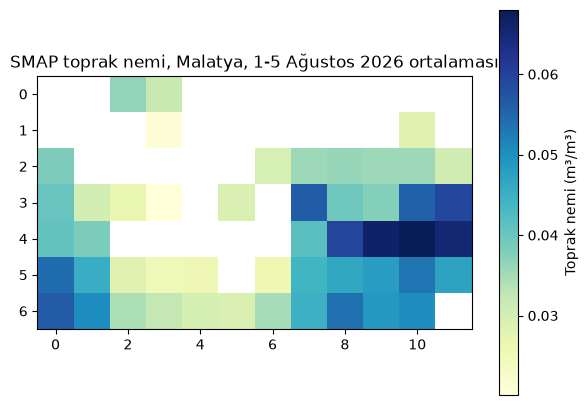

In [6]:
import h5py, numpy as np, matplotlib.pyplot as plt

try:
    f.close()
except Exception:
    pass

BATI, GUNEY, DOGU, KUZEY = MALATYA_BBOX

def oku(dosya, grup, sm_adi, lat_adi, lon_adi, kalite_adi):
    with h5py.File(dosya, "r") as h:
        g = h[grup]
        lat = g[lat_adi][:]
        lon = g[lon_adi][:]
        sm = g[sm_adi][:]
        kalite = g[kalite_adi][:]
    return lat, lon, sm, kalite

# Izgara sabit, bu yüzden bbox maskesini ilk dosyadan bir kez çıkarıyoruz
lat, lon, _, _ = oku(files[0], "Soil_Moisture_Retrieval_Data_AM",
                     "soil_moisture", "latitude", "longitude", "retrieval_qual_flag")
maske = (lat >= GUNEY) & (lat <= KUZEY) & (lon >= BATI) & (lon <= DOGU)
satir, sutun = np.where(maske)
r0, r1, c0, c1 = satir.min(), satir.max() + 1, sutun.min(), sutun.max() + 1
print("Kesit boyutu:", (r1 - r0, c1 - c0), "piksel")

gunluk = []
for dosya in files:
    for grup, sm, la, lo, kal in [
        ("Soil_Moisture_Retrieval_Data_AM", "soil_moisture", "latitude", "longitude", "retrieval_qual_flag"),
        ("Soil_Moisture_Retrieval_Data_PM", "soil_moisture_dca_pm", "latitude_pm", "longitude_pm", "retrieval_qual_flag_dca_pm"),
    ]:
        _, _, s, k = oku(dosya, grup, sm, la, lo, kal)
        kesit = s[r0:r1, c0:c1].astype("float32")
        kk = k[r0:r1, c0:c1]
        kesit[(kesit < 0) | ((kk & 1) != 0)] = np.nan   # -9999 ve düşük kaliteyi ele
        gunluk.append(kesit)

ortalama = np.nanmean(np.stack(gunluk), axis=0)
print("Geçerli değer sayısı:", np.isfinite(ortalama).sum(), "/", ortalama.size)

plt.figure(figsize=(7, 5))
plt.imshow(ortalama, cmap="YlGnBu")
plt.colorbar(label="Toprak nemi (m³/m³)")
plt.title("SMAP toprak nemi, Malatya, 1-5 Ağustos 2026 ortalaması")
plt.show()

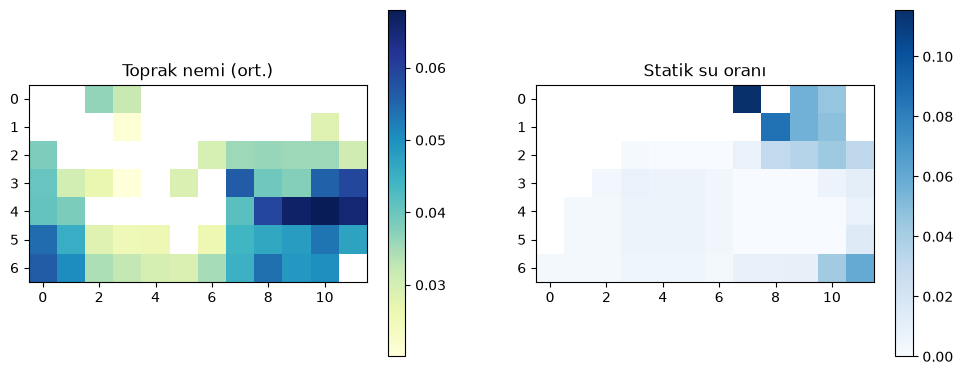

Kaydedildi: 84 satır


In [8]:
import os

with h5py.File(files[0], "r") as h:
    g = h["Soil_Moisture_Retrieval_Data_AM"]
    su = g["static_water_body_fraction"][r0:r1, c0:c1].astype("float32")
    lat_k = g["latitude"][r0:r1, c0:c1]
    lon_k = g["longitude"][r0:r1, c0:c1]
su[su < 0] = np.nan

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
a = ax[0].imshow(ortalama, cmap="YlGnBu"); ax[0].set_title("Toprak nemi (ort.)"); plt.colorbar(a, ax=ax[0])
b = ax[1].imshow(su, cmap="Blues"); ax[1].set_title("Statik su oranı"); plt.colorbar(b, ax=ax[1])
plt.show()

os.makedirs("data/malatya", exist_ok=True)
tablo = np.column_stack([lat_k.ravel(), lon_k.ravel(), ortalama.ravel(), su.ravel()])
np.savetxt(
    "data/malatya/smap_ornek_1-5_agustos.csv", tablo,
    delimiter=",", header="lat,lon,toprak_nemi_ort,su_orani", comments="",
    fmt="%.5f", encoding="utf-8",
)
print("Kaydedildi:", tablo.shape[0], "satır")

In [9]:
for kisa in ["GPM_3IMERGDF", "GPM_3IMERGDL"]:
    r = earthaccess.search_data(
        short_name=kisa,
        bounding_box=MALATYA_BBOX,
        temporal=("2026-08-01", "2026-09-30"),
    )
    print(kisa, "->", len(r), "granül")

GPM_3IMERGDF -> 0 granül
GPM_3IMERGDL -> 61 granül


In [11]:
imerg = earthaccess.search_data(
    short_name="GPM_3IMERGDL",
    bounding_box=MALATYA_BBOX,
    temporal=("2026-08-01", "2026-08-05"),
)
print(len(imerg), "granül")
imerg_files = earthaccess.download(imerg, "data/imerg/")

with h5py.File(imerg_files[0], "r") as h:
    h.visititems(lambda n, o: print(n, o.shape, o.dtype) if isinstance(o, h5py.Dataset) else None)

5 granül


QUEUEING TASKS | :   0%|          | 0/5 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/5 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/5 [00:00<?, ?it/s]

MWprecipitation (1, 3600, 1800) float32
MWprecipitation_cnt (1, 3600, 1800) int8
MWprecipitation_cnt_cond (1, 3600, 1800) int8
lat (1800,) float64
lon (3600,) float32
nv (2,) >f4
precipitation (1, 3600, 1800) float32
precipitation_cnt (1, 3600, 1800) int8
precipitation_cnt_cond (1, 3600, 1800) int8
probabilityLiquidPrecipitation (1, 3600, 1800) int8
randomError (1, 3600, 1800) float32
randomError_cnt (1, 3600, 1800) int8
time (1,) float64
time_bnds (1, 2) float64


Birim: ['mm/day']
Kesit: 7 x 11 piksel
20260801 bölge ortalaması: 0.0 mm/gün
20260802 bölge ortalaması: 0.0 mm/gün
20260803 bölge ortalaması: 0.0 mm/gün
20260804 bölge ortalaması: 0.0 mm/gün
20260805 bölge ortalaması: 0.0 mm/gün


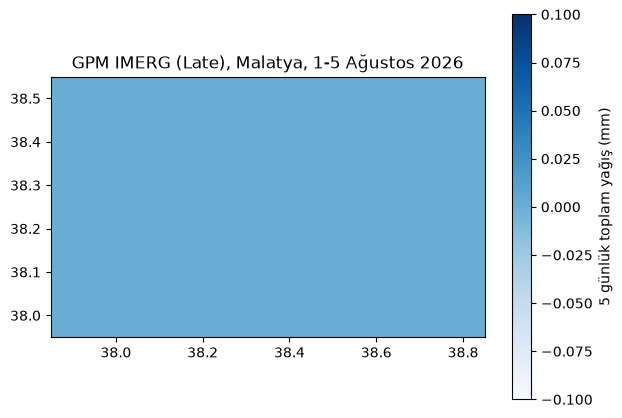

Kaydedildi: 77 satır


In [12]:
import re

with h5py.File(imerg_files[0], "r") as h:
    lat = h["lat"][:]
    lon = h["lon"][:]
    print("Birim:", h["precipitation"].attrs.get("units"))

i_lat = np.where((lat >= GUNEY) & (lat <= KUZEY))[0]
i_lon = np.where((lon >= BATI) & (lon <= DOGU))[0]
la0, la1 = i_lat.min(), i_lat.max() + 1
lo0, lo1 = i_lon.min(), i_lon.max() + 1
print("Kesit:", la1 - la0, "x", lo1 - lo0, "piksel")

tarihler, gunluk = [], []
for p in imerg_files:
    with h5py.File(p, "r") as h:
        x = h["precipitation"][0, lo0:lo1, la0:la1].astype("float32")
    x = x.T                      # (enlem, boylam)
    x[x < 0] = np.nan            # eksik veri
    gunluk.append(x)
    tarihler.append(re.search(r"(\d{8})-S", str(p)).group(1))

yigin = np.stack(gunluk)
toplam = np.nansum(yigin, axis=0)
gunluk_ort = np.nanmean(yigin, axis=(1, 2))

for t, g in zip(tarihler, gunluk_ort):
    print(t, "bölge ortalaması:", round(float(g), 2), "mm/gün")

plt.figure(figsize=(7, 5))
plt.imshow(toplam, cmap="Blues", origin="lower",
           extent=[lon[lo0], lon[lo1 - 1], lat[la0], lat[la1 - 1]])
plt.colorbar(label="5 günlük toplam yağış (mm)")
plt.title("GPM IMERG (Late), Malatya, 1-5 Ağustos 2026")
plt.show()

lon_k, lat_k = np.meshgrid(lon[lo0:lo1], lat[la0:la1])
tablo = np.column_stack([lat_k.ravel(), lon_k.ravel(), toplam.ravel()])
np.savetxt("data/malatya/imerg_ornek_1-5_agustos.csv", tablo, delimiter=",",
           header="lat,lon,yagis_toplam_mm", comments="", fmt="%.4f", encoding="utf-8")
print("Kaydedildi:", tablo.shape[0], "satır")

92 granül


QUEUEING TASKS | :   0%|          | 0/92 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/92 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/92 [00:00<?, ?it/s]

Toplam yağış (3 ay, bölge ort.): 304.8 mm


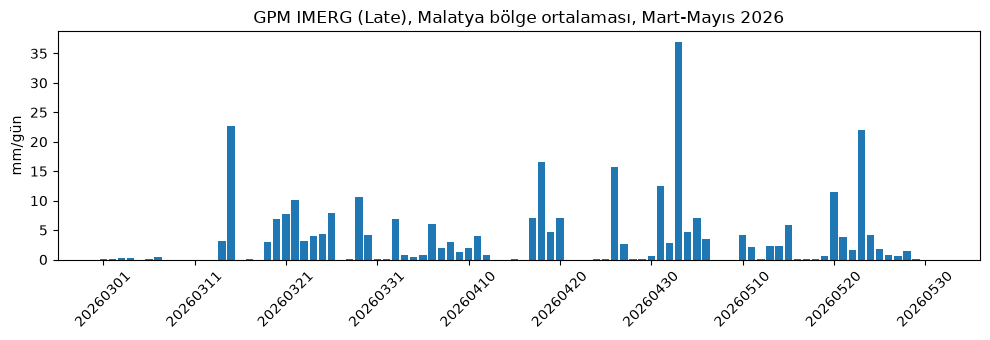

Kaydedildi: 92 gün


In [14]:
imerg_bahar = earthaccess.search_data(
    short_name="GPM_3IMERGDL",
    bounding_box=MALATYA_BBOX,
    temporal=("2026-03-01", "2026-05-31"),
)
print(len(imerg_bahar), "granül")
bahar_files = earthaccess.download(imerg_bahar, "data/imerg/")

tarih, ort = [], []
for p in bahar_files:
    with h5py.File(p, "r") as h:
        x = h["precipitation"][0, lo0:lo1, la0:la1].astype("float32")
    x[x < 0] = np.nan
    tarih.append(re.search(r"(\d{8})-S", str(p)).group(1))
    ort.append(np.nanmean(x))

ort = np.array(ort)
print("Toplam yağış (3 ay, bölge ort.):", round(float(np.nansum(ort)), 1), "mm")

plt.figure(figsize=(10, 3.5))
plt.bar(range(len(ort)), ort)
plt.xticks(range(0, len(tarih), 10), [tarih[i] for i in range(0, len(tarih), 10)], rotation=45)
plt.ylabel("mm/gün")
plt.title("GPM IMERG (Late), Malatya bölge ortalaması, Mart-Mayıs 2026")
plt.tight_layout()
plt.show()

with open("data/malatya/imerg_gunluk_mart-mayis.csv", "w", encoding="utf-8") as f:
    f.write("tarih,yagis_mm\n")
    for t, v in zip(tarih, ort):
        f.write(f"{t},{v:.3f}\n")

print("Kaydedildi:", len(tarih), "gün")